# Activity 7: Tree-based models (decision tree, random forest, gradient boosting)

**Tuesday · Block 2** · Kernel: `nwcst` · About 20–30 minutes

The hands-on part of the tree-based models lecture. You will fit three models on the same data
as Block 1: a single decision tree, a random forest and gradient boosting. The steps are the
same as in Activity 6, so the RMSEs are directly comparable with Ridge, LASSO and Elastic Net.

You will draw a tree and read it, watch a forest average its trees, follow boosting round by
round, and compare which series the trees rely on with what LASSO kept. Cells marked
**YOUR TURN** are the ones you change.

## Preparation

The data are the shared files for the three Tuesday blocks, already in `data/`. They were
prepared exactly as in Activity 5 (build) and in the nowcast tool: each series is seasonally
adjusted at its own frequency and turned into a growth rate (quarter on quarter for GDP,
month on month for the predictors, then averaged within each quarter). The money and credit
series are left in nominal terms, because T&T's CPI only starts in 2015 and deflating would
cut ten quarters from an already short sample.

| File | What it holds |
|---|---|
| `blocks_quarterly.csv` | Real GDP growth (`RGDP0000`), a `sample` column (`train` / `test`) and 15 predictors |
| `blocks_meta.csv` | Ticker, short label, group and description of each predictor |

The split is fixed so that every block, in Python and in R, is scored on the same quarters:
**train** = 2013Q1 to 2023Q1 (41 quarters), **test** = 2023Q2 to 2026Q1 (12 quarters).

Run as is; there is nothing to change here.

Trees split on thresholds, so they do not care about the scale of a predictor. We still use
the same standardized X as Block 1, so the comparison with LASSO at the end uses identical
inputs.

In [167]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

# Relative folders: run this notebook from activity/ (or sols/)
PATH_DATA = os.path.join("..", "data")
PATH_OUTPUT = os.path.join("..", "output")
os.makedirs(PATH_OUTPUT, exist_ok=True)

# Cumulative results table, shared by every block and by the R activities
RESULTS_FILE = os.path.join(PATH_OUTPUT, "workshop_results.csv")
LANGUAGE = "Python"

target_variable = "RGDP0000"

data = pd.read_csv(os.path.join(PATH_DATA, "blocks_quarterly.csv"),
                   parse_dates=["date"], index_col="date")
meta = pd.read_csv(os.path.join(PATH_DATA, "blocks_meta.csv"))

predictors = [c for c in data.columns if c not in (target_variable, "sample")]
LABELS = meta.set_index("ticker")["label"].to_dict()
labels = [LABELS.get(c, c) for c in predictors]

train = data[data["sample"] == "train"]
test = data[data["sample"] == "test"]

# Raw (unscaled) predictors
X_train_raw = train[predictors]
X_test_raw = test[predictors]
y_train = train[target_variable]
y_obs = test[target_variable]

# Standardize with the TRAIN mean and standard deviation only (the test quarters stay unseen)
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler().fit(X_train_raw)
X_train = pd.DataFrame(scaler.transform(X_train_raw), index=train.index, columns=predictors)
X_test = pd.DataFrame(scaler.transform(X_test_raw), index=test.index, columns=predictors)

The helper functions below (`rmse`, `comparison_table`, `save_result`, `results_table`,
`plot_observed_predicted`, `data_summary`) are the same in all three blocks. Run and move on.

In [168]:
from datetime import datetime

RESULT_COLS = ["block", "activity", "language", "model", "rmse_test", "notes"]


def rmse(observed, predicted):
    """Root mean squared error."""
    return float(np.sqrt(np.mean((np.asarray(observed) - np.asarray(predicted)) ** 2)))


def comparison_table(predicted, name="Predicted"):
    """Observed vs predicted on the test sample, with the error in percentage points."""
    t = pd.DataFrame({"Observed": y_obs, name: np.asarray(predicted)}, index=y_obs.index)
    t["Error (pp)"] = t[name] - t["Observed"]
    return t.round(3)


def save_result(block, activity, model, rmse_value, notes=""):
    """Add or replace one row of the workshop results table.

    A row is identified by (activity, language, model): re-running a cell replaces its
    row instead of duplicating it. Rows written by the R activities are kept untouched.
    """
    row = pd.DataFrame([{
        "block": int(block), "activity": activity, "language": LANGUAGE,
        "model": model, "rmse_test": round(float(rmse_value), 4), "notes": notes,
    }])
    if os.path.exists(RESULTS_FILE) and os.path.getsize(RESULTS_FILE) > 0:
        prev = pd.read_csv(RESULTS_FILE)
        same = ((prev["activity"] == activity) & (prev["language"] == LANGUAGE)
                & (prev["model"] == model))
        row = pd.concat([prev[~same], row], ignore_index=True)
    os.makedirs(os.path.dirname(RESULTS_FILE), exist_ok=True)
    row[RESULT_COLS].to_csv(RESULTS_FILE, index=False)
    print(f"Saved: {model} ({activity}, {LANGUAGE})  RMSE = {float(rmse_value):.4f}")


def results_table():
    """Everything saved so far, by every block and language, best to worst."""
    if not os.path.exists(RESULTS_FILE) or os.path.getsize(RESULTS_FILE) == 0:
        print("No results saved yet.")
        return pd.DataFrame(columns=RESULT_COLS)
    t = pd.read_csv(RESULTS_FILE)
    t = t.sort_values("rmse_test").reset_index(drop=True)
    print(t.to_string())
    return t


def plot_observed_predicted(predicted, name, color="#C0392B", ax=None):
    """Observed vs predicted GDP growth on the test sample."""
    if ax is None:
        _, ax = plt.subplots(figsize=(9, 4))
    ax.plot(y_obs.index, y_obs.values, "o-", color="#2C3E50", lw=2, label="Observed")
    ax.plot(y_obs.index, np.asarray(predicted), "s--", color=color, lw=2, label=name)
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_ylabel("Real GDP growth, q/q (%)")
    ax.set_title(f"Observed vs predicted: {name}")
    ax.legend(frameon=False)
    ax.grid(alpha=0.25)
    plt.tight_layout()
    return ax


def data_summary():
    """Print the state of the data, to check that everything loaded."""
    print("=" * 66)
    print("DATA READY FOR THE ACTIVITY")
    print("=" * 66)
    print(f"Target     : {target_variable} (real GDP growth, q/q %)")
    print(f"Predictors : {len(predictors)}")
    print(f"Train      : {train.index.min():%Y-%m} to {train.index.max():%Y-%m} "
          f"({len(train)} quarters)")
    print(f"Test       : {test.index.min():%Y-%m} to {test.index.max():%Y-%m} "
          f"({len(test)} quarters)")
    print("=" * 66)
    return pd.DataFrame({
        "label": labels,
        "group": meta.set_index("ticker").loc[predictors, "group"].values,
        "train mean": X_train_raw.mean().values,
        "train std": X_train_raw.std().values,
    }, index=predictors).round(2)

In [169]:
data_summary();

DATA READY FOR THE ACTIVITY
Target     : RGDP0000 (real GDP growth, q/q %)
Predictors : 15
Train      : 2013-03 to 2023-03 (41 quarters)
Test       : 2023-06 to 2026-03 (12 quarters)


In [170]:
# Reference: what has been saved so far (Block 1, and the R activities if they have run)
results_table();

   block activity language              model  rmse_test                                       notes
0      2     act7   Python      Random Forest     2.1718            n_estimators=200, max_features=6
1      1     act6   Python              Ridge     2.1910             alpha=92.37, TimeSeriesSplit(5)
2      1     act6   Python        Elastic Net     2.2109                     alpha=1.0, l1_ratio=0.5
3      0     act6   Python              AR(1)     2.2819  phi=-0.142, uses last quarter's actual GDP
4      2     act7   Python      Decision Tree     2.2878             max_depth=5, min_samples_leaf=2
5      0     act6   Python       Mean (train)     2.3543                             naive benchmark
6      2     act7   Python  Gradient Boosting     2.3908        learning_rate=0.15, n_estimators=200
7      1     act6   Python              LASSO     2.5918                                   alpha=0.1
8      1     act6   Python                OLS     3.0418                  no penalty, stand

## A single tree

A regression tree splits the sample in two again and again, each time choosing the variable
and threshold that most reduce the error inside the resulting groups. At the end it predicts
the average (here, the median) GDP growth of the train quarters that landed in each leaf.

| Parameter | Effect |
|---|---|
| `max_depth` | How many chained splits are allowed. Deeper means more flexible and more prone to memorizing noise. |
| `min_samples_split` | Minimum number of quarters needed to split a node. Higher means shorter trees. |
| `min_samples_leaf` | Minimum number of quarters in a leaf. Higher means less overfitted predictions. |
| `criterion` | How each candidate split is scored. Absolute error is more robust to outliers than squared error, which matters with 2020 in the sample. |

With 41 train quarters the risk of overfitting is high, so the pruning parameters are not a
technical detail: they are what makes the model usable.

In [ ]:
from sklearn.tree import DecisionTreeRegressor

# Reference tree, shallow, just to have a starting point
tree_ref = DecisionTreeRegressor(
    criterion="absolute_error", max_depth=4,
    min_samples_split=6, min_samples_leaf=2, random_state=42,
).fit(X_train, y_train)

print(f"RMSE with max_depth=4 (reference): {rmse(y_obs, tree_ref.predict(X_test)):.4f}")

### Chart 1: Where overfitting starts

Rather than trying depths one at a time, the cell below runs through all of them and plots the
two errors together. The train error always falls, because a deep enough tree can memorize
every quarter. The test error falls at first and then turns up. The depth where they part is
where the model stops learning and starts memorizing; that is the one to use.

,max_depth,RMSE train,RMSE test
0,1,2.3754,2.3614
1,2,2.1426,2.3580
2,3,1.9799,2.3561
3,4,1.8513,2.3602
4,5,1.8233,2.2878
5,6,1.6696,2.7318
6,8,1.4998,2.6328
7,10,1.3836,2.6474


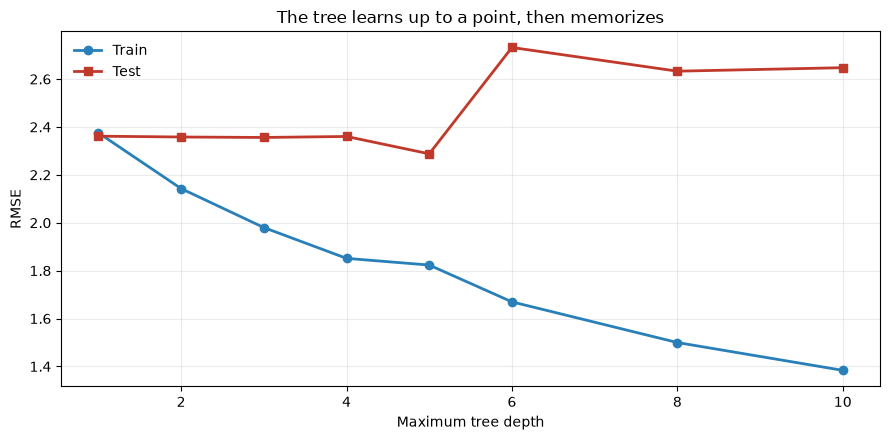

In [172]:
depths = [1, 2, 3, 4, 5, 6, 8, 10]
err_train, err_test = [], []

for p in depths:
    m = DecisionTreeRegressor(
        criterion="absolute_error", max_depth=p,
        min_samples_split=6, min_samples_leaf=2, random_state=42,
    ).fit(X_train, y_train)
    err_train.append(rmse(y_train, m.predict(X_train)))
    err_test.append(rmse(y_obs, m.predict(X_test)))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(depths, err_train, "o-", color="#2980B9", lw=2, label="Train")
ax.plot(depths, err_test, "s-", color="#C0392B", lw=2, label="Test")
ax.set_xlabel("Maximum tree depth")
ax.set_ylabel("RMSE")
ax.set_title("The tree learns up to a point, then memorizes")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
plt.tight_layout()

pd.DataFrame({"max_depth": depths, "RMSE train": err_train, "RMSE test": err_test}).round(4)

### YOUR TURN: fix the final model

Pick from the chart the depth where the test error is lowest (just before it turns up) and set
it here. This becomes the official tree of the block, and it is the one drawn below.

In [173]:
# ============ YOUR TURN ============
# Copy here the depth you chose from the chart above.
max_depth = 5
min_samples_leaf = 2
# ===================================

tree = DecisionTreeRegressor(
    criterion="absolute_error",
    max_depth=max_depth,
    min_samples_split=3,
    min_samples_leaf=min_samples_leaf,
    random_state=100,
).fit(X_train, y_train)

pred_tree = tree.predict(X_test)
rmse_tree = rmse(y_obs, pred_tree)
rmse_tree_train = rmse(y_train, tree.predict(X_train))

print(f"RMSE train : {rmse_tree_train:.4f}")
print(f"RMSE test  : {rmse_tree:.4f}")
print(f"Gap        : {rmse_tree - rmse_tree_train:.4f}  <- if it grows, the tree is overfitting")
print(f"Actual depth: {tree.get_depth()}   (the limit was {max_depth})")
print(f"Leaves      : {tree.get_n_leaves()}")
print(f"Distinct values predicted on the 12 test quarters: {len(np.unique(pred_tree.round(6)))}")

save_result(2, "act7", "Decision Tree", rmse_tree, f"max_depth={max_depth}, min_samples_leaf={min_samples_leaf}")

RMSE train : 1.7898
RMSE test  : 2.2878
Gap        : 0.4979  <- if it grows, the tree is overfitting
Actual depth: 5   (the limit was 5)
Leaves      : 7
Distinct values predicted on the 12 test quarters: 2
Saved: Decision Tree (act7, Python)  RMSE = 2.2878


### Chart 2: Inside the tree

This is the teaching advantage of trees over every other model in the workshop: you can draw
them and read them. Each box shows the variable and threshold used to split (in standard
deviations, since X is standardized), how many train quarters reached it, and the value the
model predicts.

Notice also how few distinct values the tree can predict: one per leaf, and most test quarters
fall into one or two leaves, so its forecast is a step function.

Look at the root: it is the single split that reduces the error the most. Find where 2020Q2
ends up, and compare the root variable with the last survivor of the LASSO path in Block 1.

,GDP growth,leaf,fitted
date,,,
2020-03-01,-2.53,10,-3.47
2020-06-01,-12.34,1,-8.01
2020-09-01,4.33,8,-0.13
2020-12-01,-0.05,8,-0.13


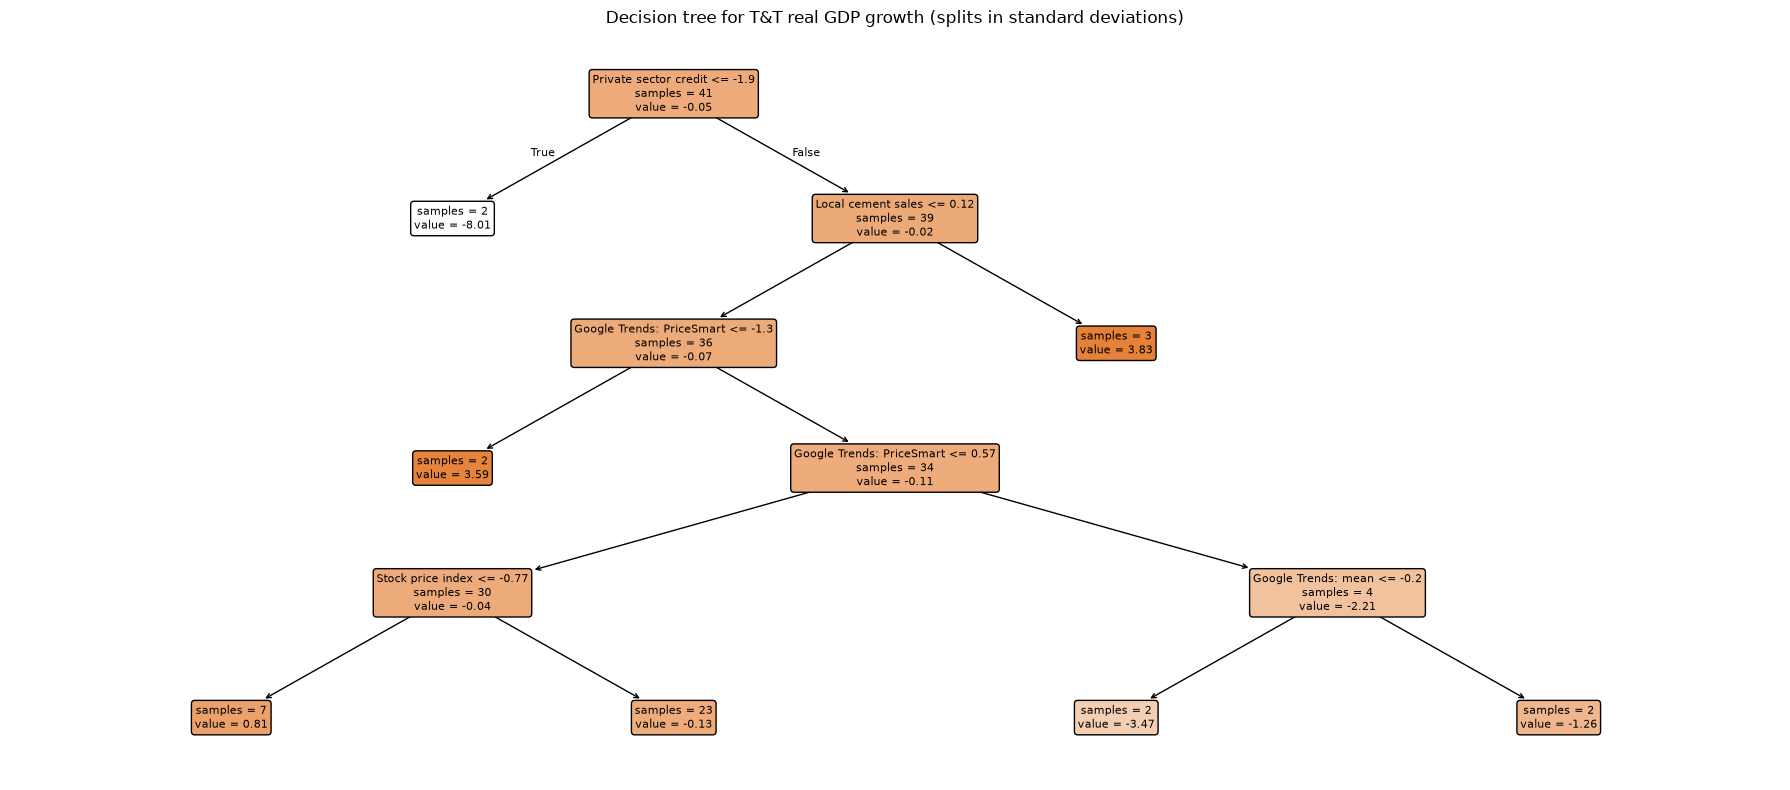

In [174]:
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(18, 8))
plot_tree(
    tree,
    feature_names=labels,
    filled=True,
    rounded=True,
    fontsize=8,
    impurity=False,
    precision=2,
    ax=ax,
)
ax.set_title("Decision tree for T&T real GDP growth (splits in standard deviations)")
plt.tight_layout()

# Which leaf does each 2020 quarter fall in?
leaf_2020 = pd.Series(tree.apply(X_train), index=X_train.index)
pd.DataFrame({"GDP growth": y_train, "leaf": leaf_2020,
              "fitted": tree.predict(X_train)}).loc["2020"].round(2)

## Random forest

Instead of one tree, the forest grows many, each on a bootstrap sample of the quarters and
considering only a random subset of variables at each split. That double randomization makes
the trees wrong in different ways, and averaging them partly cancels the errors.

| Parameter | Effect |
|---|---|
| `n_estimators` | Number of trees. More is better up to a point; above about 200 the gain is marginal. |
| `max_features` | How many variables are candidates at each split. The main source of diversity across trees. |
| `min_samples_leaf` | Regularization of each individual tree. |

### YOUR TURN: grow the forest

With `max_features=3`, each split of each tree can only choose among 3 of the 15 variables,
drawn at random. Below you will see what that restriction buys. Try 1, 3, 5 and 15 (15 makes
every tree see every variable, which is called bagging).

The cell also asks for `oob_score=True`. A random forest can validate itself without touching
the test sample: each tree is trained on a bootstrap sample that leaves out about a third of
the quarters, and those left-out quarters can be used to score that tree as if they were new
data. The average of those scores is `oob_score_`, an R², a second opinion on how well the
model generalizes. An R² below zero means a poor fit on the quarters it did not see; 2020 is
one reason.

In [175]:
from sklearn.ensemble import RandomForestRegressor

# ============ YOUR TURN ============
# Number of trees and number of candidate variables at each split.
n_estimators = 200
max_features = 6
# ===================================

rf = RandomForestRegressor(
    n_estimators=n_estimators,
    max_features=max_features,
    criterion="absolute_error",
    min_samples_split=4,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1,
    oob_score=True,
).fit(X_train, y_train)

pred_rf = rf.predict(X_test)
rmse_rf = rmse(y_obs, pred_rf)

print(f"RMSE, random forest : {rmse_rf:.4f}   (single tree: {rmse_tree:.4f})")
print(f"Out-of-bag R2 (OOB) : {rf.oob_score_:.3f}   <- internal validation, test sample not used")

save_result(2, "act7", "Random Forest", rmse_rf,
            f"n_estimators={n_estimators}, max_features={max_features}")

RMSE, random forest : 2.1718   (single tree: 2.2878)
Out-of-bag R2 (OOB) : -0.204   <- internal validation, test sample not used
Saved: Random Forest (act7, Python)  RMSE = 2.1718


### Chart 3: Inside the forest

Each grey line is one tree's prediction on the test sample, and the green line is their
average, which is what the random forest reports. Each tree on its own is erratic, because it
saw different quarters and different variables, but they err in different directions and
averaging cancels much of it.

The right panel shows the RMSE of every tree. The forest beats most of its own trees, and the
single tree above, without any of its components being especially good.

The forest beats 91% of its own trees


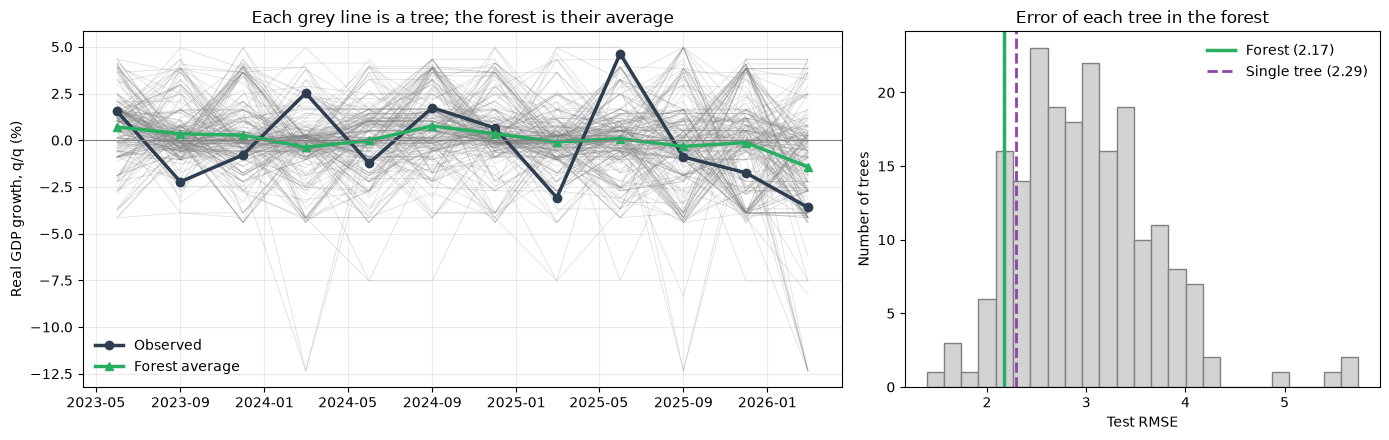

In [176]:
# Prediction of each tree (the trees were fitted without column names, hence .values)
per_tree = np.array([t.predict(X_test.values) for t in rf.estimators_])
rmse_trees = np.array([rmse(y_obs, p) for p in per_tree])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1.6, 1]})

for p in per_tree:
    ax1.plot(y_obs.index, p, color="grey", lw=0.6, alpha=0.25)
ax1.plot(y_obs.index, y_obs.values, "o-", color="#2C3E50", lw=2.5, label="Observed")
ax1.plot(y_obs.index, pred_rf, "^-", color="#27AE60", lw=2.5, label="Forest average")
ax1.axhline(0, color="grey", lw=0.8)
ax1.set_ylabel("Real GDP growth, q/q (%)")
ax1.set_title("Each grey line is a tree; the forest is their average")
ax1.legend(frameon=False)
ax1.grid(alpha=0.25)

ax2.hist(rmse_trees, bins=25, color="lightgrey", edgecolor="grey")
ax2.axvline(rmse_rf, color="#27AE60", lw=2.5, label=f"Forest ({rmse_rf:.2f})")
ax2.axvline(rmse_tree, color="#8E44AD", lw=2, ls="--", label=f"Single tree ({rmse_tree:.2f})")
ax2.set_xlabel("Test RMSE")
ax2.set_ylabel("Number of trees")
ax2.set_title("Error of each tree in the forest")
ax2.legend(frameon=False)
plt.tight_layout()

print(f"The forest beats {(rmse_trees > rmse_rf).mean():.0%} of its own trees")

## Gradient boosting

Here the trees are not averaged but chained: each new tree is fitted to the errors left by the
sum of the previous ones, so the model corrects its own mistakes stage by stage.

| Parameter | Effect |
|---|---|
| `n_estimators` | Number of sequential stages (rounds). |
| `learning_rate` | How much each tree is allowed to contribute. Low values need more rounds but generalize better. |

The two move together: lowering the learning rate without adding rounds leaves the model
half-fitted.

### Exploring the pair of parameters

Three small tables. First, more rounds at a fixed, fairly high learning rate. Second, a lower
learning rate at a fixed number of rounds. Third, the four corners: few or many rounds, high
or low learning rate.

In [177]:
from sklearn.ensemble import GradientBoostingRegressor


def explore_gbt(pairs):
    rows = []
    for lr, n in pairs:
        m = GradientBoostingRegressor(
            n_estimators=n, learning_rate=lr, loss="absolute_error",
            min_samples_split=6, min_samples_leaf=3, random_state=42,
        ).fit(X_train, y_train)
        rows.append({"learning_rate": lr, "n_estimators": n,
                     "RMSE (test)": round(rmse(y_obs, m.predict(X_test)), 4)})
    return pd.DataFrame(rows)


# 1) More rounds at learning_rate = 0.15
explore_gbt([(0.15, 50), (0.15, 100), (0.15, 200), (0.15, 400)])

,learning_rate,n_estimators,RMSE (test)
0,0.15,50,2.3712
1,0.15,100,2.3075
2,0.15,200,2.3908
3,0.15,400,2.3723


In [178]:
# 2) Lower learning rate at 100 rounds
explore_gbt([(0.15, 100), (0.10, 100), (0.05, 100), (0.02, 100)])

,learning_rate,n_estimators,RMSE (test)
0,0.15,100,2.3075
1,0.10,100,2.3425
2,0.05,100,2.1903
3,0.02,100,2.1883


In [179]:
# 3) The four corners
explore_gbt([(0.15, 100), (0.02, 100), (0.15, 600), (0.02, 600)])

,learning_rate,n_estimators,RMSE (test)
0,0.15,100,2.3075
1,0.02,100,2.1883
2,0.15,600,2.3809
3,0.02,600,2.2688


### YOUR TURN: fix the final model

Copy the pair from the tables above with the best RMSE.

In [180]:
# ============ YOUR TURN ============
# Copy here the (learning_rate, n_estimators) pair you chose from the tables above.
learning_rate = 0.15
n_estimators_gb = 200
# ===================================

gbt = GradientBoostingRegressor(
    n_estimators=n_estimators_gb,
    learning_rate=learning_rate,
    loss="absolute_error",
    min_samples_split=6,
    min_samples_leaf=3,
    random_state=42,
).fit(X_train, y_train)

pred_gbt = gbt.predict(X_test)
rmse_gbt = rmse(y_obs, pred_gbt)

print(f"RMSE, gradient boosting: {rmse_gbt:.4f}")
save_result(2, "act7", "Gradient Boosting", rmse_gbt,
            f"learning_rate={learning_rate}, n_estimators={n_estimators_gb}")

RMSE, gradient boosting: 2.3908
Saved: Gradient Boosting (act7, Python)  RMSE = 2.3908


### Chart 4: Train vs test, round by round

The train error of gradient boosting always falls, because adding a tree never worsens the
fit on data the model has already seen. The question that matters is at which round it stops
improving on data it has not seen.

`staged_predict()` answers it: instead of only the final prediction with all trees added up,
it returns the cumulative prediction after each round, as if training were paused at every
step. From that we compute the RMSE on both samples at every round and plot the two curves.

The result is the textbook figure from the lecture: the train curve falls and flattens, the
test curve falls, reaches a minimum and then drifts up. That minimum is the early-stopping
round, and everything after it is the model memorizing the particulars of the train quarters.
We run on purpose with many more rounds than needed so the overfitting stretch shows in full.

In [ ]:
n_rounds_long = 500
lr_long = 0.05

gbt_long = GradientBoostingRegressor(
    n_estimators=n_rounds_long,
    learning_rate=lr_long,
    loss="absolute_error",
    min_samples_split=6,
    min_samples_leaf=3,
    random_state=2,
).fit(X_train, y_train)

# staged_predict returns the cumulative prediction after each round
err_train_r = [rmse(y_train, p) for p in gbt_long.staged_predict(X_train)]
err_test_r = [rmse(y_obs, p) for p in gbt_long.staged_predict(X_test)]

best_round = int(np.argmin(err_test_r)) + 1
print(f"Round with the lowest test RMSE: {best_round} of {n_rounds_long}")
print(f"RMSE at that round            : {min(err_test_r):.4f}")
print(f"RMSE at the final round       : {err_test_r[-1]:.4f}   <- worse, from overfitting")

Round with the lowest test RMSE: 234 of 500
RMSE at that round            : 2.1272
RMSE at the final round       : 2.1376   <- worse, from overfitting


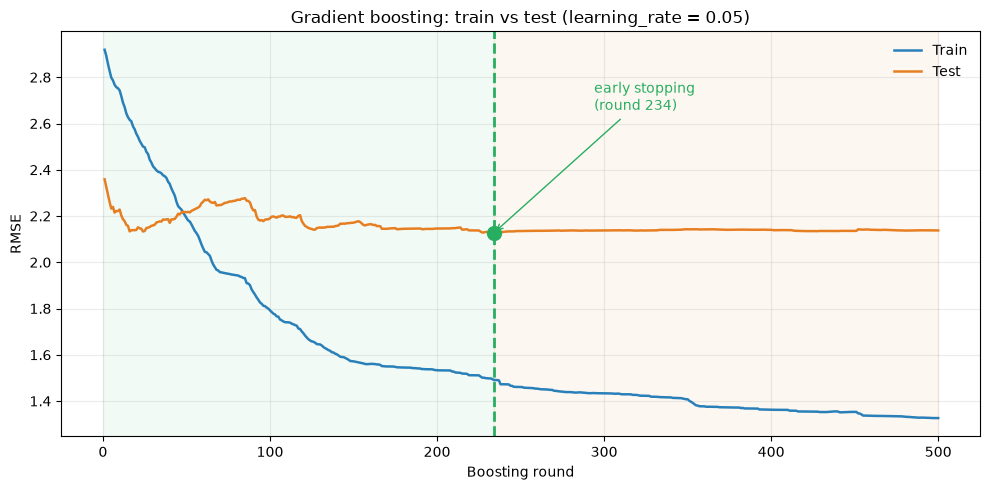

In [182]:
rounds = range(1, n_rounds_long + 1)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(rounds, err_train_r, color="#2980B9", lw=1.8, label="Train")
ax.plot(rounds, err_test_r, color="#E67E22", lw=1.8, label="Test")
ax.axvline(best_round, color="#27AE60", ls="--", lw=2)
ax.plot(best_round, min(err_test_r), "o", color="#27AE60", markersize=10)
ax.annotate(f"early stopping\n(round {best_round})",
            xy=(best_round, min(err_test_r)),
            xytext=(best_round + n_rounds_long * 0.12, min(err_test_r) * 1.25),
            color="#27AE60", fontsize=10,
            arrowprops=dict(arrowstyle="->", color="#27AE60"))
ax.axvspan(0, best_round, color="#27AE60", alpha=0.06)
ax.axvspan(best_round, n_rounds_long, color="#E67E22", alpha=0.06)
ax.set_xlabel("Boosting round")
ax.set_ylabel("RMSE")
ax.set_title(f"Gradient boosting: train vs test (learning_rate = {lr_long})")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
plt.tight_layout()

In production you do not read this chart by eye and then trim the model by hand.
`GradientBoostingRegressor` has `n_iter_no_change` and `validation_fraction`, which set aside
part of the train sample as internal validation and stop boosting on their own when the loss
stops improving for a given number of rounds. Here it was done by hand because the point is to
see the shape of the two curves, not to automate the cut.

A warning about this particular chart: the orange curve is computed on the same test sample
used to report the final RMSE, so choosing the round by looking at it is, strictly speaking,
cheating. It is for understanding the phenomenon, not for tuning a model you will report.

### Chart 5: The three predictions on the test sample

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(y_obs.index, y_obs.values, "o-", color="#2C3E50", lw=2.5, label="Observed")
ax.plot(y_obs.index, pred_tree, "s--", color="#8E44AD", lw=1.8, label="Decision tree")
ax.plot(y_obs.index, pred_rf, "^--", color="#27AE60", lw=1.8, label="Random forest")
ax.plot(y_obs.index, pred_gbt, "d--", color="#E67E22", lw=1.8, label="Gradient boosting")
ax.axhline(0, color="grey", lw=0.8)
ax.set_ylabel("Real GDP growth, q/q (%)")
ax.set_title("Tree-based models on the test sample")
ax.legend(frameon=False, ncol=3)
ax.grid(alpha=0.25)
plt.tight_layout()

pd.DataFrame({"Observed": y_obs, "Tree": pred_tree, "Forest": pred_rf,
              "Boosting": pred_gbt}).round(2)

## Wrap-up: the cumulative table

In [184]:
results_table();

   block activity language              model  rmse_test                                       notes
0      2     act7   Python      Random Forest     2.1718            n_estimators=200, max_features=6
1      1     act6   Python              Ridge     2.1910             alpha=92.37, TimeSeriesSplit(5)
2      1     act6   Python        Elastic Net     2.2109                     alpha=1.0, l1_ratio=0.5
3      0     act6   Python              AR(1)     2.2819  phi=-0.142, uses last quarter's actual GDP
4      2     act7   Python      Decision Tree     2.2878             max_depth=5, min_samples_leaf=2
5      0     act6   Python       Mean (train)     2.3543                             naive benchmark
6      2     act7   Python  Gradient Boosting     2.3908        learning_rate=0.15, n_estimators=200
7      1     act6   Python              LASSO     2.5918                                   alpha=0.1
8      1     act6   Python                OLS     3.0418                  no penalty, stand

### Extra chart: Variable importance vs LASSO coefficients

This chart closes the arc of the two blocks. Tree models report how much each variable reduced
the error across all the splits it took part in, a way to measure its contribution without
imposing any functional form. LASSO gets to the same question by the opposite route, removing
coefficients from a linear model.

When both agree on the same two or three series, the result is solid and can be defended in
front of a central bank board. When they differ, there are two possible reasons worth telling
apart: the variable enters GDP non-linearly (a threshold, a crisis-only effect), so the linear
model could not see it; or the trees used it to memorize a few unusual quarters, such as
2020Q2. Because X is standardized, the LASSO side is not biased toward volatile series.

#### What variable importance is and how it is computed

A tree works by sorting quarters. It starts with all of them together, where GDP growth is
very dispersed, and at each step separates them into two groups using one variable and one
threshold, for example quarters with LNG production growing above 2% and quarters below. If
the split is good, GDP growth inside each group is more alike than before. The importance of a
variable answers a simple question: of everything the model managed to sort, how much is owed
to that variable?

**The contribution of one split.** How disordered a group is, is measured by its *impurity*.
In this notebook (`criterion="absolute_error"`) it is the average distance of GDP growth from
the group's median, in percentage points; with `criterion="squared_error"` it would be the
variance. When a node $t$ with $N_t$ quarters is split into a left group $L$ and a right group
$R$, the reduction in disorder is

$$
\Delta I(t) = \frac{N_t}{N}\left[\, I(t) - \frac{N_L}{N_t}\, I(L) - \frac{N_R}{N_t}\, I(R) \,\right]
$$

The bracket compares the impurity before the split with the size-weighted average impurity of
the two groups after it. It is exactly the criterion the tree uses to decide how to split:
among all variables and thresholds it picks the one that makes the bracket largest. So the
importance computes nothing new; it only keeps the books on what each decision the tree
already took gained. The factor $N_t/N$, where $N$ is the total number of quarters, makes a
split that affects the whole sample weigh more than one affecting three or four quarters deep
in the tree.

**From splits to importance.** Add up the contributions of all splits made on each variable,
average across the trees of the forest, and divide by the total so that importances sum to one:

$$
\text{Imp}_j = \frac{1}{B}\sum_{b=1}^{B}\;\sum_{t \,\in\, b \,:\, v(t)=j} \Delta I(t),
\qquad \sum_j \text{Imp}_j = 1
$$

where $B$ is the number of trees and $v(t)$ the variable used at node $t$.

**An example with round numbers.** At the start, GDP growth in the train quarters is on
average 1.5 pp from its median. The tree first splits on LNG production and, inside the two
resulting groups, that average distance falls to 1.0 pp. The split contributes 0.5 pp, at full
weight because it involves every quarter. Then, in a group holding a third of the sample, it
splits on M1 and the distance falls from 0.9 to 0.6 pp, contributing 0.3 × 1/3 = 0.1 pp. The
tree reduced 0.6 pp in total, 0.5 from LNG and 0.1 from M1, so their importances are 0.83 and
0.17.

**How to read the number.** An importance of 0.83 means that 83% of all the reduction in GDP
dispersion the model achieved came from splits on that variable. It says how much the model
used it to separate high-growth from low-growth quarters, not how much GDP moves when the
variable changes. It has no sign either: a variable can be very important without the chart
telling you whether it goes with more or less growth.

In gradient boosting the computation is the same, except that each tree sorts the errors left
by the previous ones, so importance measures how much each variable helped correct them. To
put LASSO on the same chart its coefficients are normalized in absolute value,
$|\beta_j| / \sum_k |\beta_k|$, but keep in mind they measure different things: the coefficient
is an effect (points of GDP per standard deviation of the variable) and the importance is a
contribution to sorting the data.

**Cautions.** Because importances always sum to one, a model that barely reduces the error
still hands out 100% among its variables, so read them together with the RMSE. They are
computed on the train sample, so a variable the tree used to memorize noise (or 2020) also
accumulates importance. When two series are highly correlated, such as the two credit series,
the trees use them almost interchangeably and each looks less important than the pair really
is. And with 41 quarters the ranking can change if you move the random seed, so look at which
variables are at the top, not at small differences between them.

,Random forest,Gradient boosting,LASSO (relative |coef|)
Local cement sales,0.118,0.059,0.368
Google Trends: PriceSmart,0.106,0.070,0.000
Private sector credit,0.105,0.065,0.406
Exports to the US,0.093,0.101,0.174
Money supply M1,0.070,0.067,0.000
Brent oil price,0.068,0.092,0.052
Stock price index,0.056,0.044,0.000
Prime lending rate,0.055,0.069,0.000
Consumer credit,0.055,0.054,0.000
Night lights: country,0.053,0.088,0.000


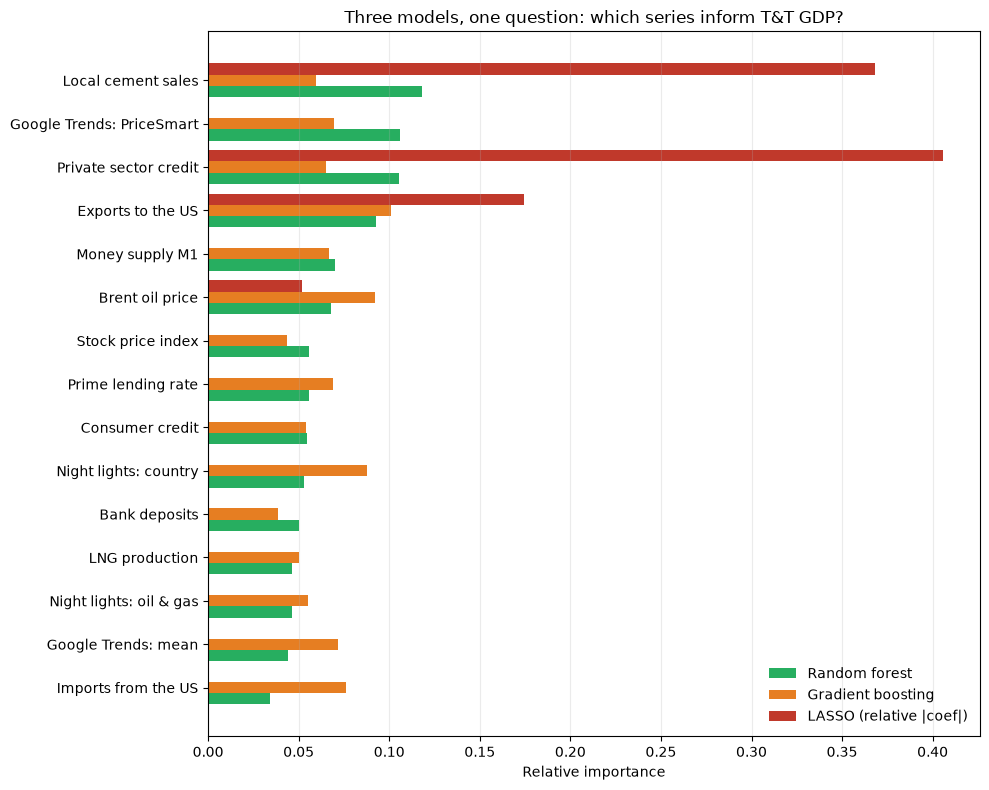

In [185]:
from sklearn.linear_model import Lasso

# Re-fit the LASSO from Activity 6 to compare side by side (alpha chosen in Block 1)
alpha_lasso = 0.5
lasso = Lasso(alpha=alpha_lasso, max_iter=50000).fit(X_train, y_train)

importances = pd.DataFrame({
    "Random forest": rf.feature_importances_,
    "Gradient boosting": gbt.feature_importances_,
}, index=labels)

# LASSO coefficients in relative magnitude, so the scales are visually comparable
coef_abs = np.abs(lasso.coef_)
importances["LASSO (relative |coef|)"] = coef_abs / coef_abs.sum() if coef_abs.sum() > 0 else coef_abs

order = importances["Random forest"].sort_values().index
imp = importances.loc[order]

fig, ax = plt.subplots(figsize=(10, 8))
yy = np.arange(len(imp))
height = 0.26
palette = ["#27AE60", "#E67E22", "#C0392B"]

for i, (col, color) in enumerate(zip(imp.columns, palette)):
    ax.barh(yy + i * height - height, imp[col], height, label=col, color=color)

ax.set_yticks(yy)
ax.set_yticklabels(imp.index)
ax.set_xlabel("Relative importance")
ax.set_title("Three models, one question: which series inform T&T GDP?")
ax.legend(frameon=False)
ax.grid(alpha=0.25, axis="x")
plt.tight_layout()

importances.sort_values("Random forest", ascending=False).round(3)